In [1]:
import sys
# sys.path.insert(0, '../../Utilities/')

# from jax.example_libraries import optimizers
import jax.numpy as jnp
import numpy as np
from jax import grad, jit, vmap, value_and_grad, hessian
from jax import random
from functools import partial
import flax.linen as nn
import jax
import optax
import pickle
from datetime import datetime
import os
import numpy as np
from scipy import sparse
import time
from jax import grad, hessian, jit, vmap, pmap
from jax.tree_util import tree_leaves
from datetime import datetime
import matplotlib.pyplot as plt
import pickle
import flax.linen as nn
import optax
import optax.tree_utils as otu
from seq_minmax_opt_class import SeqMinMaxOptProb
from my_helpers import plot_u_2D, plot_comparison_seperate_combined_u_theta, compute_errors_combined_u_theta, plot_u_theta, plot_u_theta_mesh, plot_comparison_together
from PwpHex_class import PiecewiseLinearPolynomialsHex
from PwpTetra_class import PiecewiseLinearPolynomialsTetra
from minmax_opt_class_mgnn_2d import MinMaxOptProb2D
from minmax_opt_class_mgnn import MinMaxOptProb

In [2]:
t_min = 0
t_max = 0.5
x_min = 0
x_max = 1
y_min = 0
y_max = 1

import numpy as np

def u_ref(t, x, y):
    """
    Exact solution u(t, x, y) for the 2D Burgers equation.
    """
    cond1 = x <= 0.5 - 3*t/5
    cond2 = (0.5 - 3*t/5 < x) & (x <= 0.5 - t/4)
    cond3 = (0.5 - t/4 < x) & (x <= 0.5 + t/2)
    cond4 = (0.5 + t/2 < x) & (x <= 0.5 + 4*t/5)
    cond5 = x > 0.5 + 4*t/5
    u = np.zeros_like(x)

    # Case 1
    cond1 = cond1
    u[cond1] = np.where(y[cond1] > 0.5 + 3*t[cond1]/20, -0.2, 0.5)

    # Case 2
    u[cond2] = np.where(y[cond2] > -8*x[cond2]/7 + 15/14 - 15*t[cond2]/28, -1, 0.5)

    # Case 3
    u[cond3] = np.where(y[cond3] > x[cond3]/6 + 5/12 - 5*t[cond3]/24, -1, 0.5)

    # Case 4
    u[cond4] = np.where(y[cond4] > x[cond4] - (5/(18*t[cond4])) * (x[cond4] + t[cond4] - 0.5)**2, -1, (2*x[cond4] - 1)/(2*t[cond4]))

    # Case 5
    u[cond5] = np.where(y[cond5] > 0.5 - t[cond5]/10, -1, 0.8)
    return u

def u0(x, y):
    """
    Initial condition u0(x, y).
    """
    return u_ref(t_min*np.zeros_like(x), x, y)

def u_left(t, y):
    """
    Boundary condition at x = x_min.
    """
    return u_ref(t, x_min*np.zeros_like(t), y)

def u_right(t, y):
    """
    Boundary condition at x = x_max.
    """
    return u_ref(t, x_max*np.ones_like(t), y)

def u_bottom(t, x):
    """
    Boundary condition at y = y_min.
    """
    return u_ref(t, x, y_min*np.zeros_like(t))

def u_top(t, x):
    """
    Boundary condition at y = y_max.
    """
    return u_ref(t, x, y_max*np.ones_like(t))

def res(u_quad, u_t, u_x, u_y):
    return u_t + u_quad * u_x + u_quad * u_y

N_t = 10
N_x = 9
N_y = 9
optprob = SeqMinMaxOptProb(
    input_dim=3, num_segments=3, 
    total_t_min=t_min, total_t_max=t_max, x_min=x_min, x_max=x_max, y_min=y_min, y_max=y_max,
    N_t=N_t, N_x=N_x, N_y=N_y, N_bc=128, N_ic=128,
    hidden_dims_list=[[64, 64, 64, 64, 64]], seed=0,
    sigma=10, N_perturb=50000, k_h_rf_times=2, f_adaptive_weight=2000, f_opt_kh=1,
    u0=u0, u1=u_left, u2=u_right, u3=u_bottom, u4=u_top, project="seq_minmax_burgers2D",
    lambda_ic=20.0, lambda_bc=20.0, lambda_eqn=1.0,
    gamma=0, N_test_gamma=1000, adjust_gamma=False,
    L1reg=0, sampling_method='uniform', notes='', pre_epochs=0,
    init_lrs=[1e-3, 1e-3, 1e-3], grade_epochs=[10000, 1000, 1000], decay_rates=[1e-3, 1e-3, 1e-3],
    res=res, loss_type='interior', k=0, f_plot=1000, plt_err_dist=True, plt_mesh=True,
    partition='tetra', dg_type='P1', use_importance_sampling=True, u_ref=u_ref,
    set_wandb=False
)

Adding grade 1 with hidden dims [64, 64, 64, 64, 64]
Partition type: tetra, dg_type: P1, p_dof: 4

Training segment [0.0000, 0.1667]
Skipping pre-training as pre_epochs is set to 0.

Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0
Updating importance sampling probabilities...
Grade 0, Iter 0, lambda_ic: 18.723894, lambda_bc: 18.327168, lambda_eqn: 1.079790
Updating importance sampling probabilities...
Grade 0, Iter 0, loss_eqn: 0.410655, loss_eqn_from_kh: 0.410656 loss_l1: 0.410656, loss_ibc: 2.542315


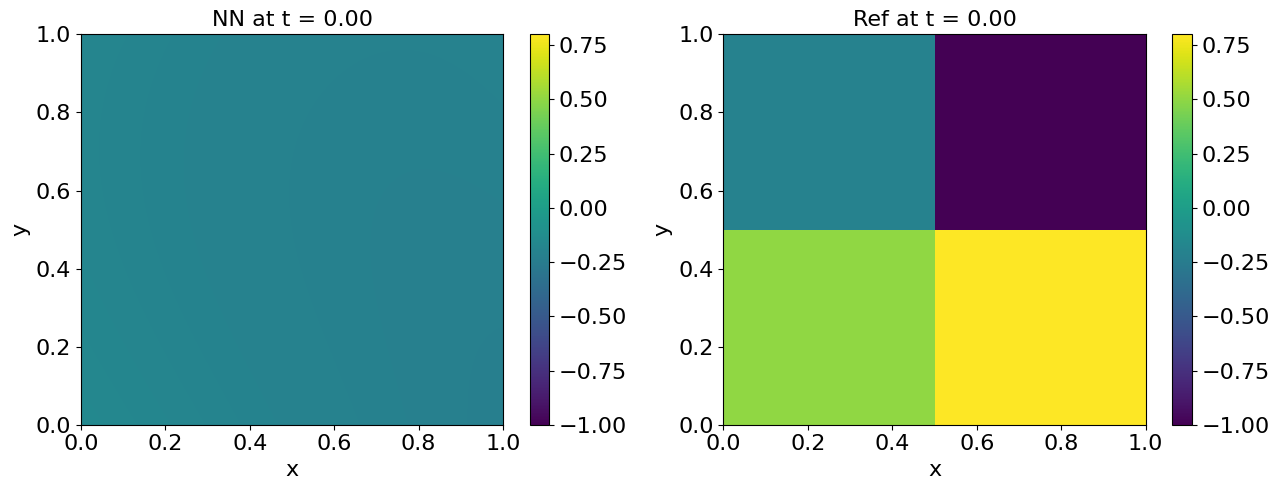

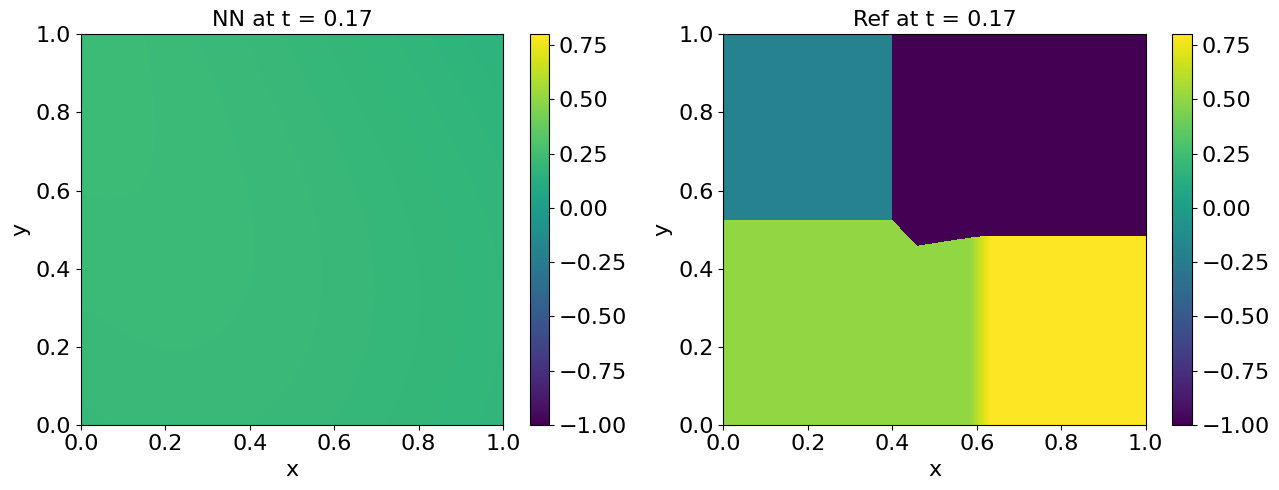

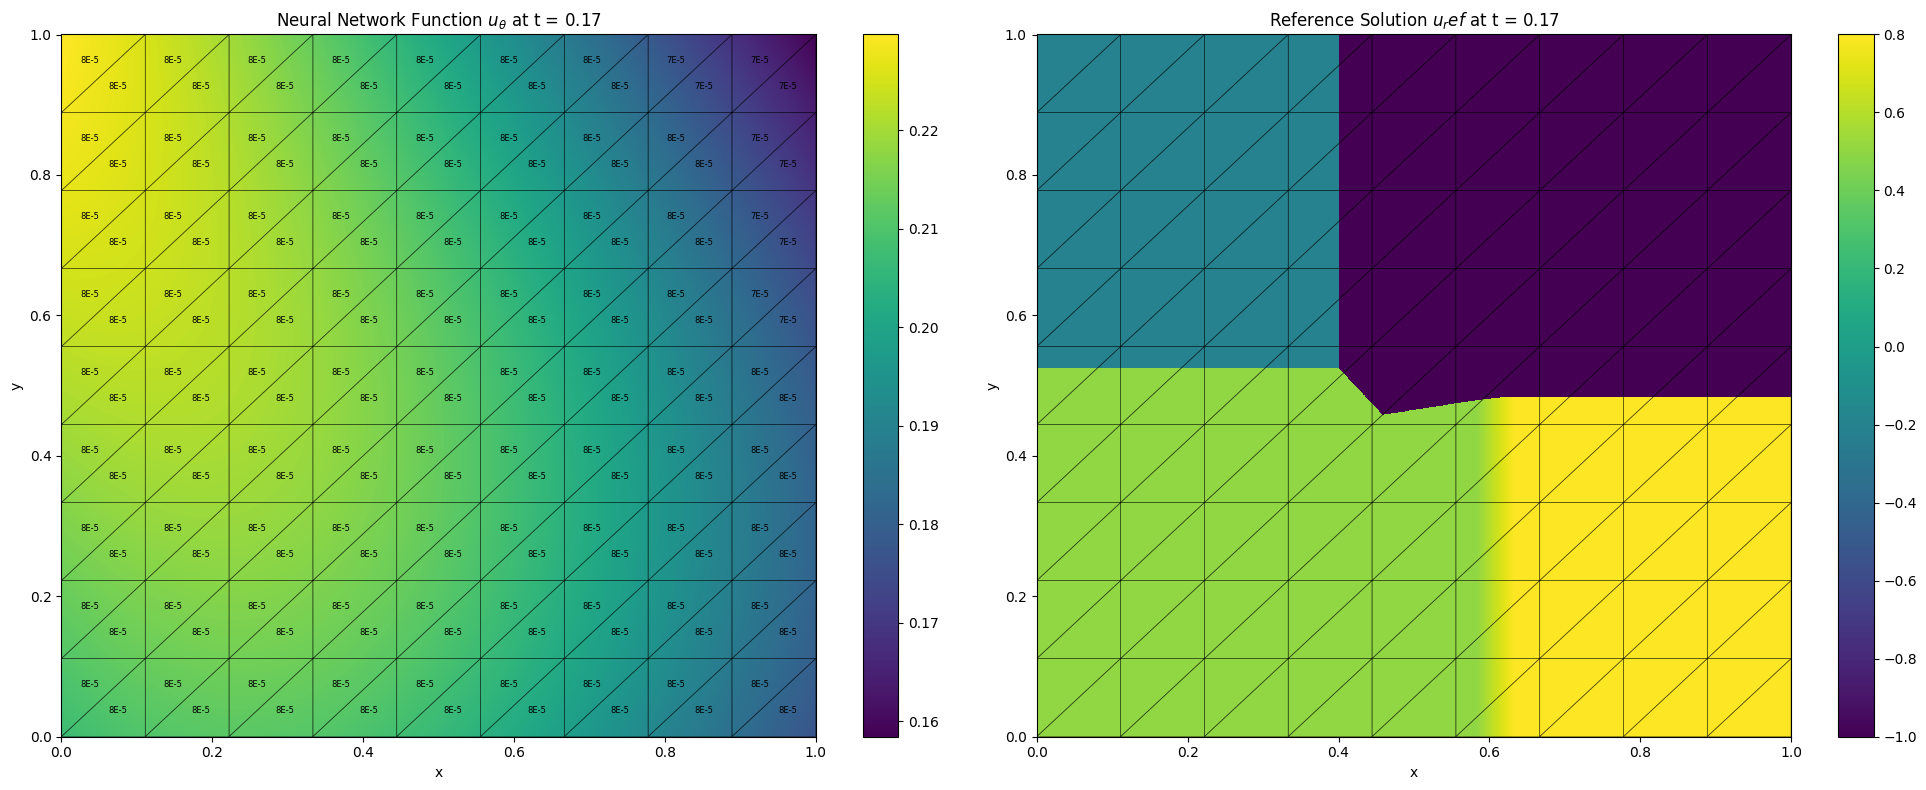

Updating importance sampling probabilities...
Grade 0, Iter 100, loss_eqn: 0.107180, loss_eqn_from_kh: 0.107180 loss_l1: 0.107180, loss_ibc: 0.512030
Updating importance sampling probabilities...
Grade 0, Iter 200, loss_eqn: 0.149950, loss_eqn_from_kh: 0.149950 loss_l1: 0.157509, loss_ibc: 0.124506
Updating importance sampling probabilities...
Grade 0, Iter 300, loss_eqn: 0.103110, loss_eqn_from_kh: 0.103110 loss_l1: 0.162023, loss_ibc: 0.053580
Updating importance sampling probabilities...
Grade 0, Iter 400, loss_eqn: 0.093401, loss_eqn_from_kh: 0.093401 loss_l1: 0.124763, loss_ibc: 0.030241
Updating importance sampling probabilities...
Grade 0, Iter 500, loss_eqn: 0.085161, loss_eqn_from_kh: 0.085161 loss_l1: 0.104874, loss_ibc: 0.018459
Updating importance sampling probabilities...
Grade 0, Iter 600, loss_eqn: 0.069437, loss_eqn_from_kh: 0.069437 loss_l1: 0.090691, loss_ibc: 0.012289
Updating importance sampling probabilities...
Grade 0, Iter 700, loss_eqn: 0.058003, loss_eqn_from_k

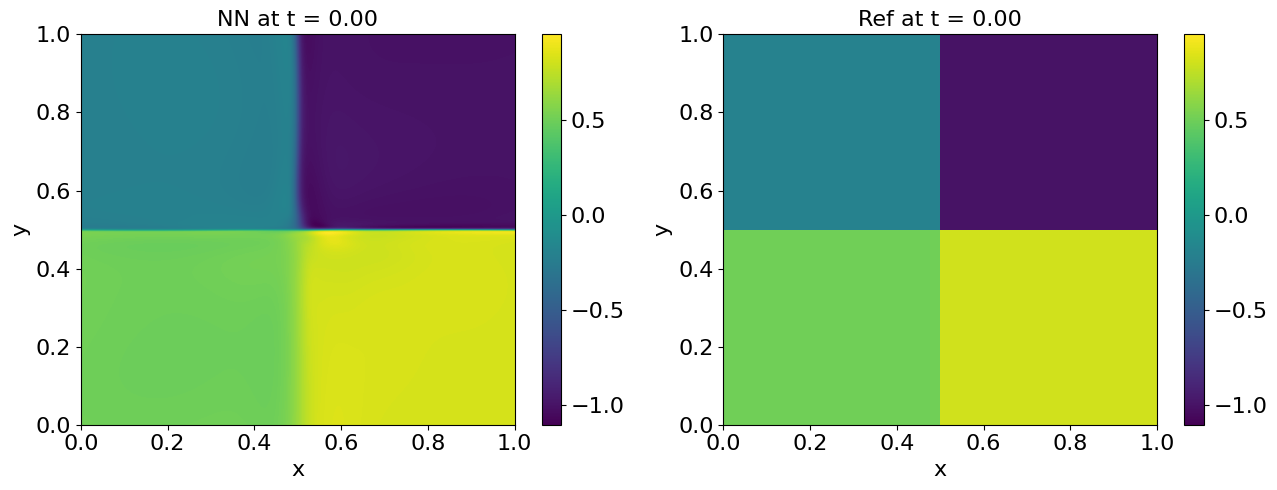

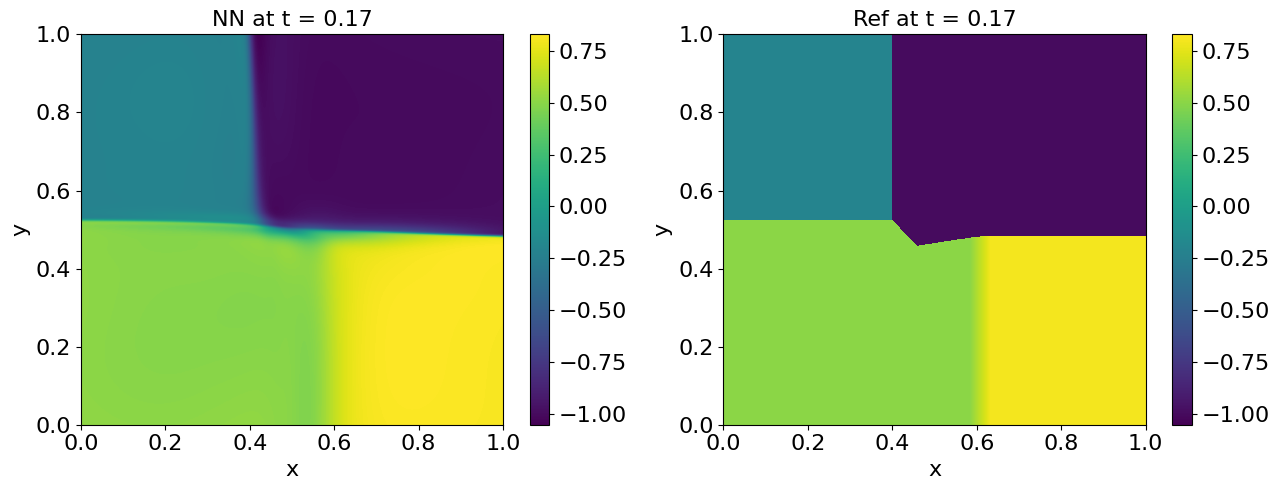

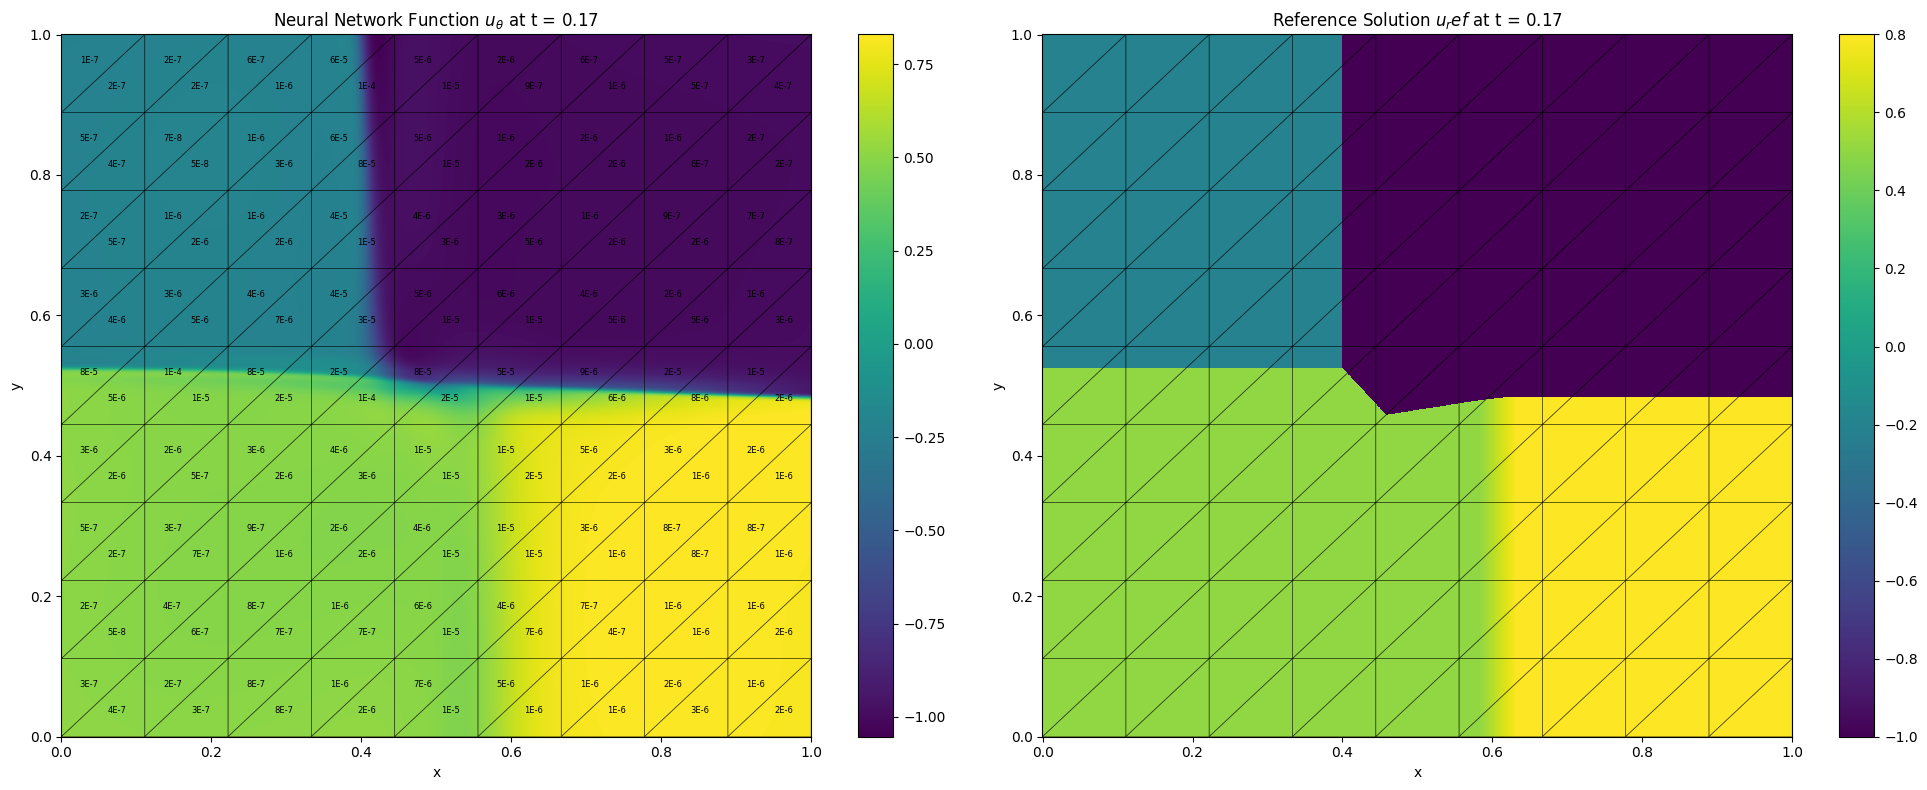

Updating importance sampling probabilities...
Grade 0, Iter 1100, loss_eqn: 0.042776, loss_eqn_from_kh: 0.042776 loss_l1: 0.069789, loss_ibc: 0.004152
Updating importance sampling probabilities...
Grade 0, Iter 1200, loss_eqn: 0.041141, loss_eqn_from_kh: 0.041141 loss_l1: 0.069514, loss_ibc: 0.003617
Updating importance sampling probabilities...
Grade 0, Iter 1300, loss_eqn: 0.037719, loss_eqn_from_kh: 0.037719 loss_l1: 0.066624, loss_ibc: 0.003524
Updating importance sampling probabilities...
Grade 0, Iter 1400, loss_eqn: 0.037380, loss_eqn_from_kh: 0.037380 loss_l1: 0.069383, loss_ibc: 0.005384
Updating importance sampling probabilities...
Grade 0, Iter 1500, loss_eqn: 0.035913, loss_eqn_from_kh: 0.035913 loss_l1: 0.067757, loss_ibc: 0.002627
Updating importance sampling probabilities...
Grade 0, Iter 1600, loss_eqn: 0.033790, loss_eqn_from_kh: 0.033790 loss_l1: 0.066304, loss_ibc: 0.002751
Updating importance sampling probabilities...
Grade 0, Iter 1700, loss_eqn: 0.032319, loss_eqn

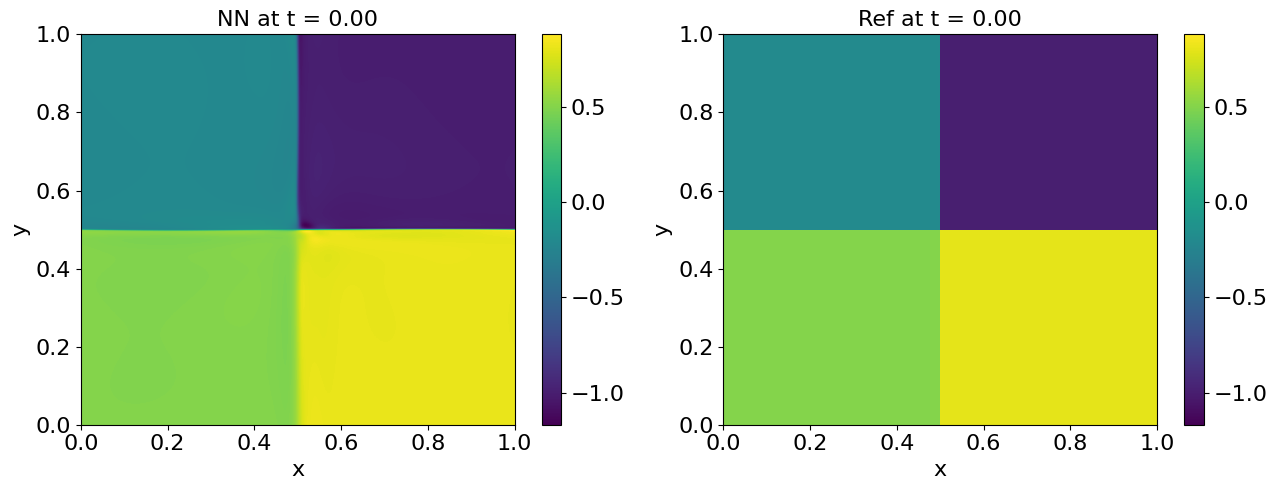

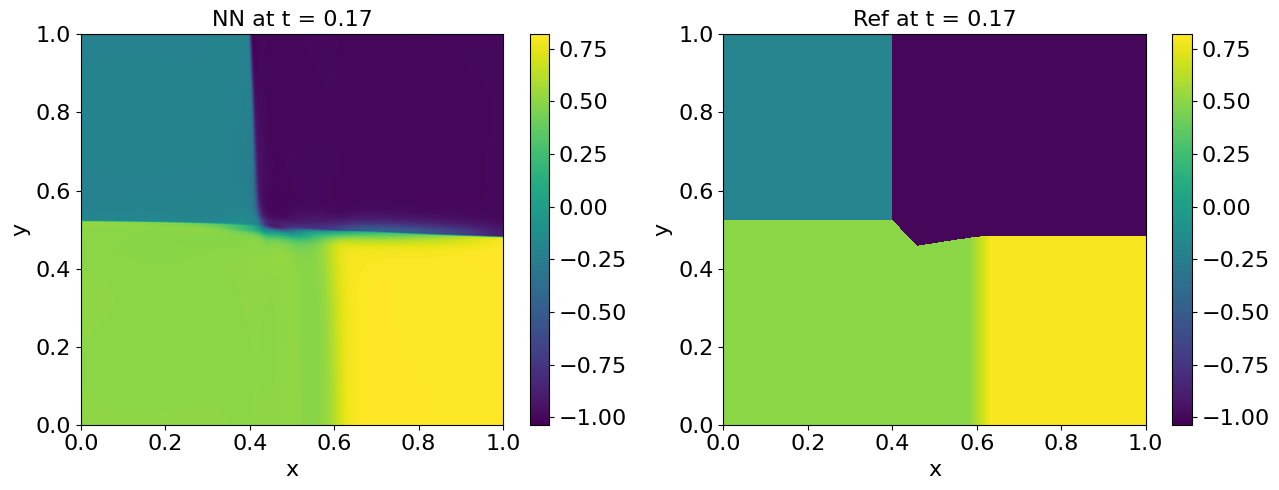

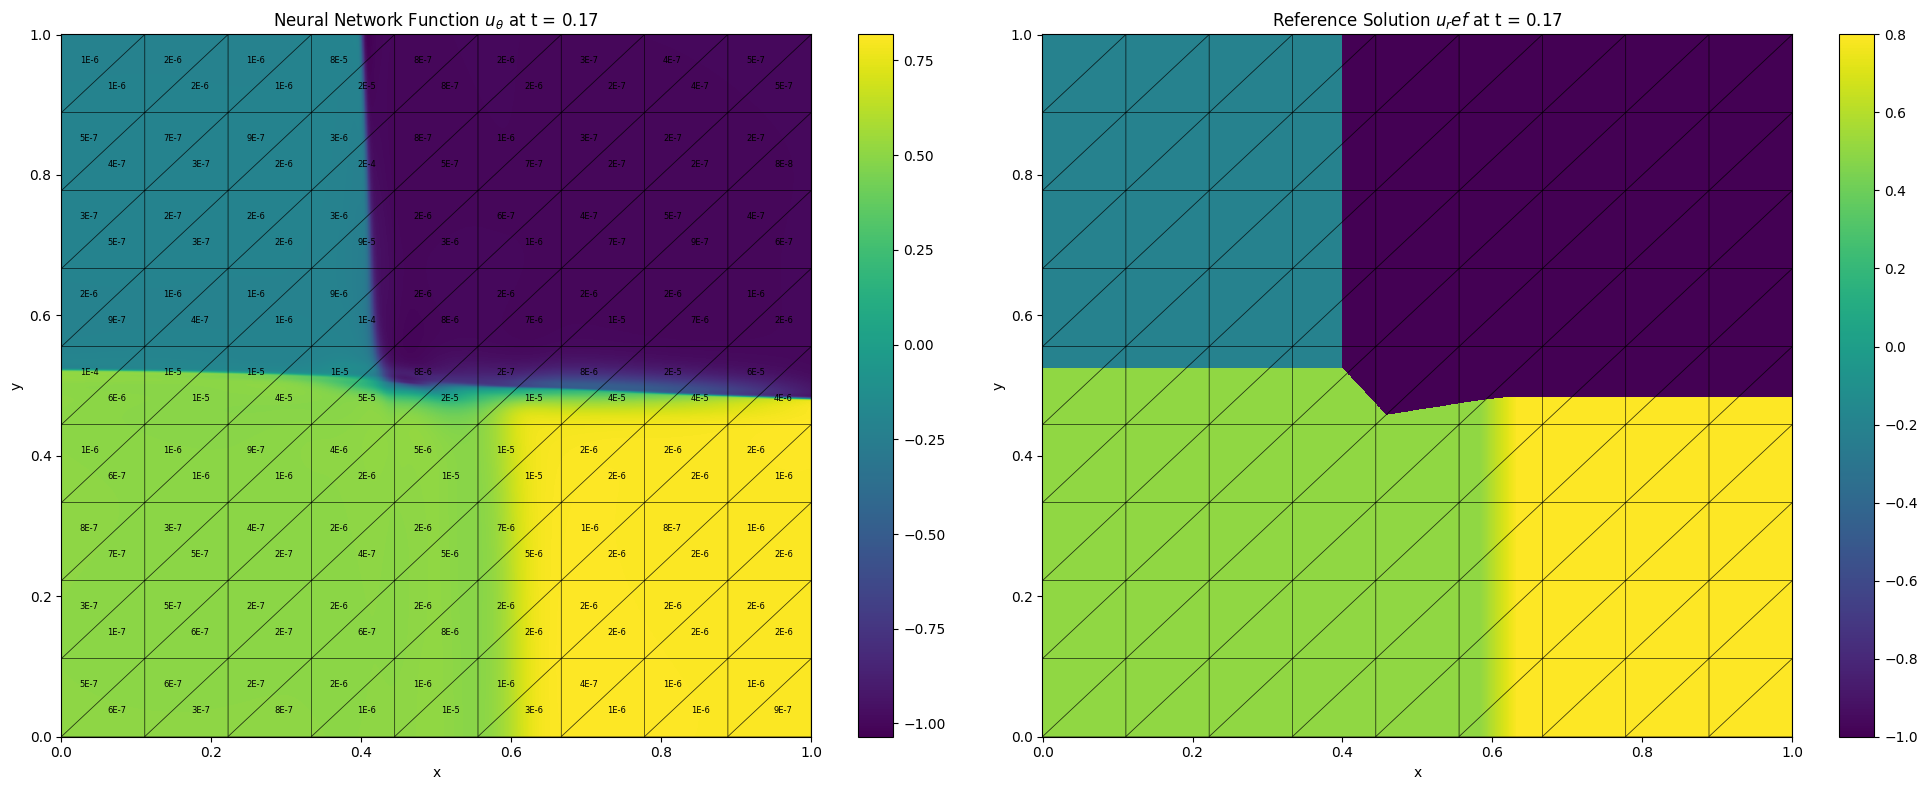

Updating importance sampling probabilities...
Grade 0, Iter 2100, loss_eqn: 0.028329, loss_eqn_from_kh: 0.028329 loss_l1: 0.067071, loss_ibc: 0.001844
Updating importance sampling probabilities...
Grade 0, Iter 2200, loss_eqn: 0.026386, loss_eqn_from_kh: 0.026386 loss_l1: 0.066492, loss_ibc: 0.001631
Updating importance sampling probabilities...
Grade 0, Iter 2300, loss_eqn: 0.028171, loss_eqn_from_kh: 0.028171 loss_l1: 0.070011, loss_ibc: 0.001788
Updating importance sampling probabilities...
Grade 0, Iter 2400, loss_eqn: 0.026975, loss_eqn_from_kh: 0.026975 loss_l1: 0.070069, loss_ibc: 0.001977
Updating importance sampling probabilities...
Grade 0, Iter 2500, loss_eqn: 0.026449, loss_eqn_from_kh: 0.026449 loss_l1: 0.069043, loss_ibc: 0.001364
Updating importance sampling probabilities...
Grade 0, Iter 2600, loss_eqn: 0.025056, loss_eqn_from_kh: 0.025056 loss_l1: 0.070162, loss_ibc: 0.001787
Updating importance sampling probabilities...
Grade 0, Iter 2700, loss_eqn: 0.024050, loss_eqn

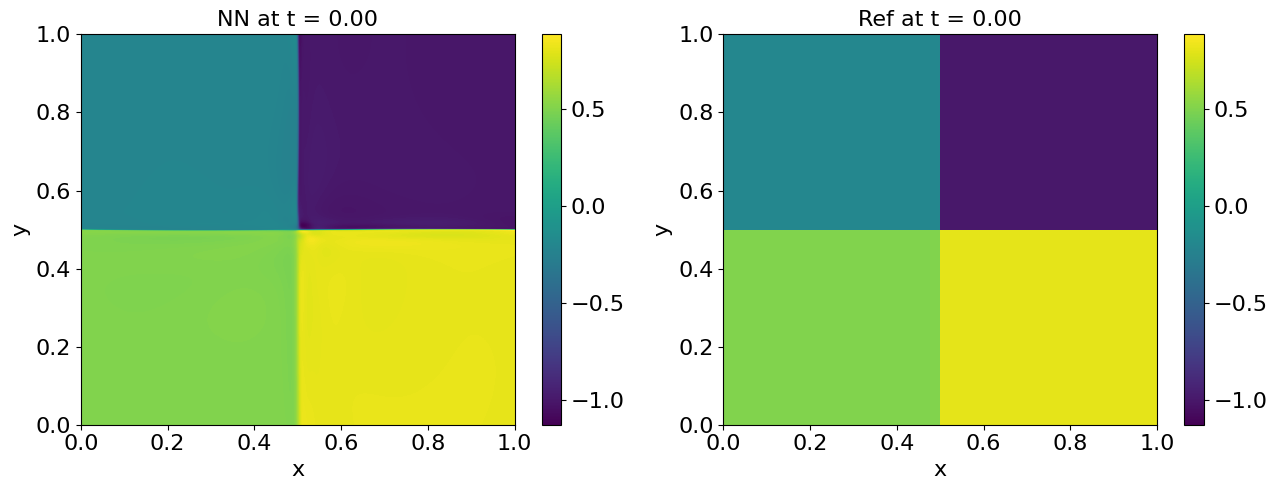

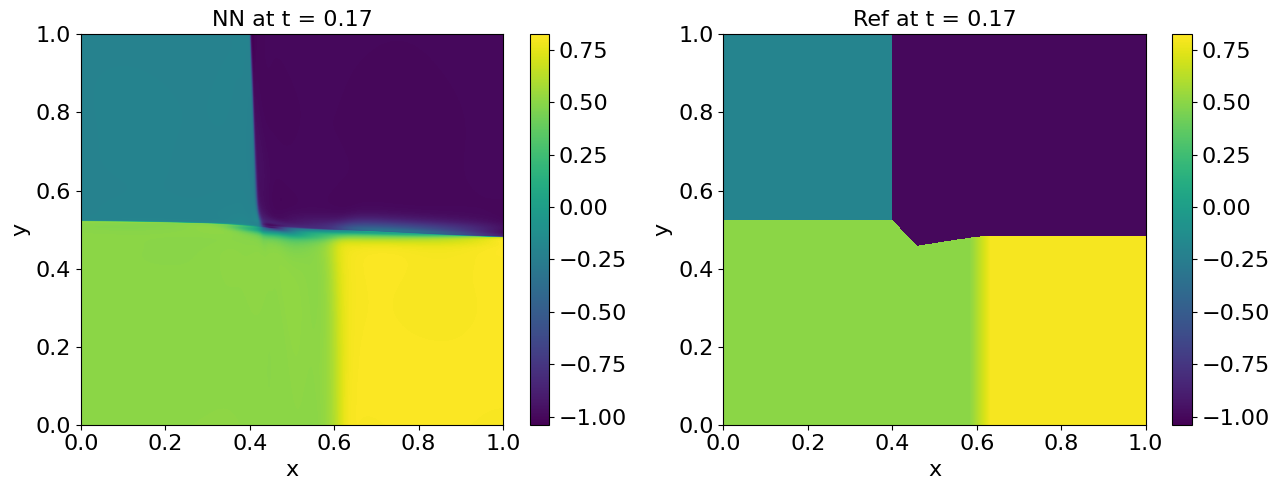

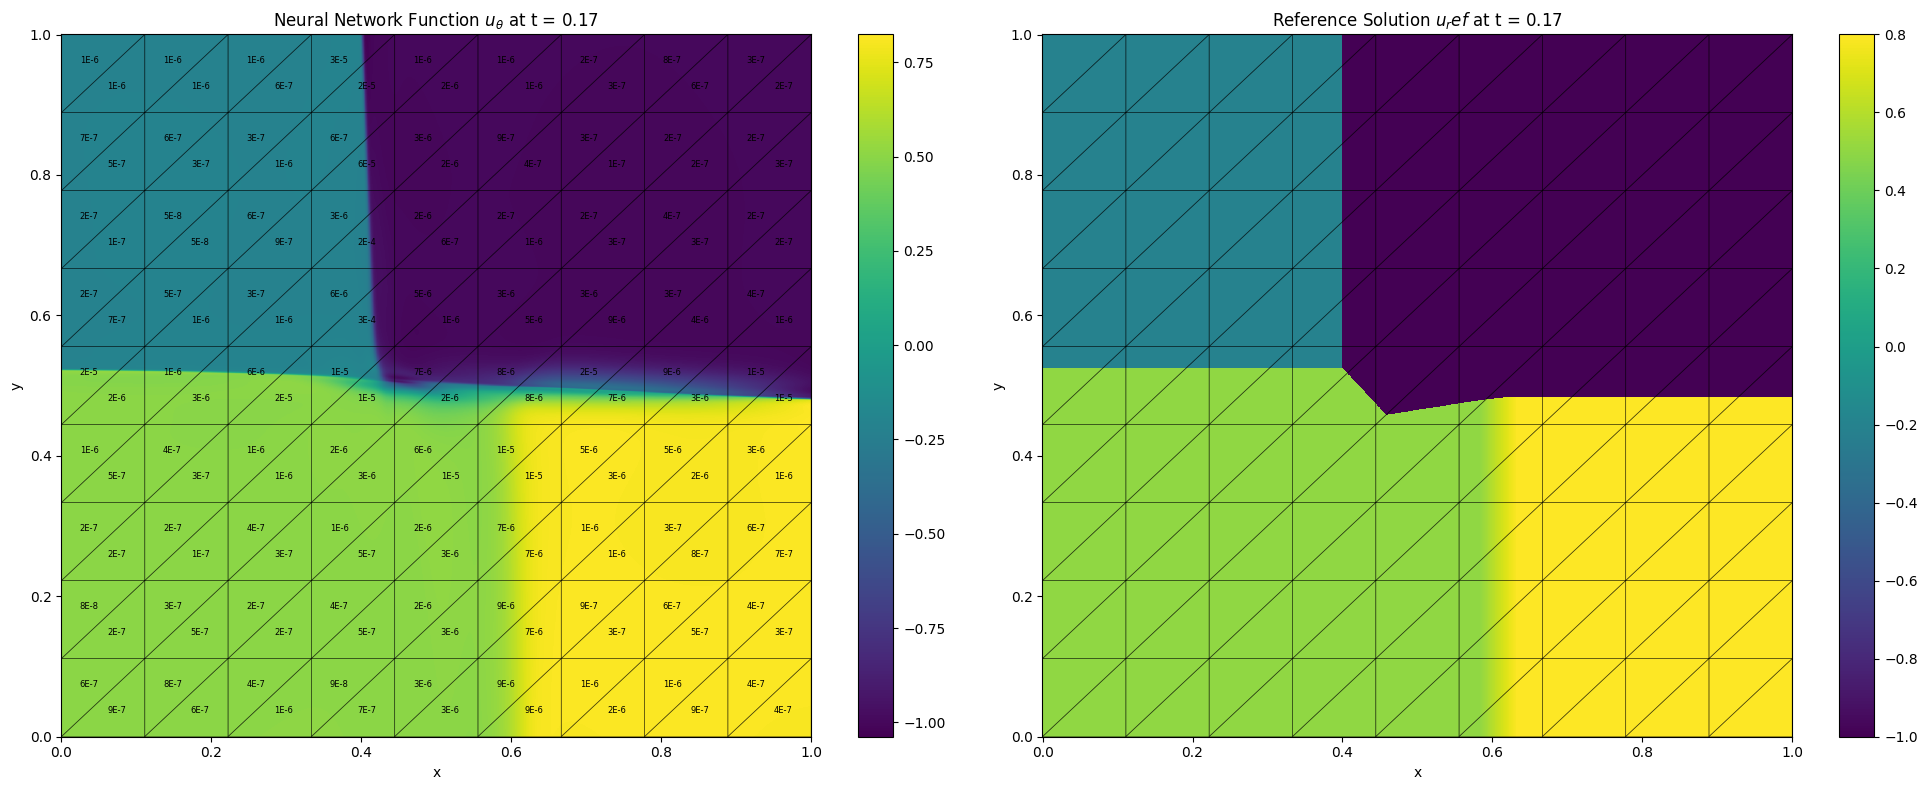

Updating importance sampling probabilities...
Grade 0, Iter 3100, loss_eqn: 0.022607, loss_eqn_from_kh: 0.022607 loss_l1: 0.070236, loss_ibc: 0.001201
Updating importance sampling probabilities...
Grade 0, Iter 3200, loss_eqn: 0.020469, loss_eqn_from_kh: 0.020469 loss_l1: 0.067906, loss_ibc: 0.001234
Updating importance sampling probabilities...
Grade 0, Iter 3300, loss_eqn: 0.019511, loss_eqn_from_kh: 0.019511 loss_l1: 0.067146, loss_ibc: 0.000991
Updating importance sampling probabilities...
Grade 0, Iter 3400, loss_eqn: 0.019041, loss_eqn_from_kh: 0.019041 loss_l1: 0.067395, loss_ibc: 0.001291
Updating importance sampling probabilities...
Grade 0, Iter 3500, loss_eqn: 0.018723, loss_eqn_from_kh: 0.018723 loss_l1: 0.067888, loss_ibc: 0.001247
Updating importance sampling probabilities...
Grade 0, Iter 3600, loss_eqn: 0.017308, loss_eqn_from_kh: 0.017308 loss_l1: 0.066320, loss_ibc: 0.001091
Updating importance sampling probabilities...
Grade 0, Iter 3700, loss_eqn: 0.018983, loss_eqn

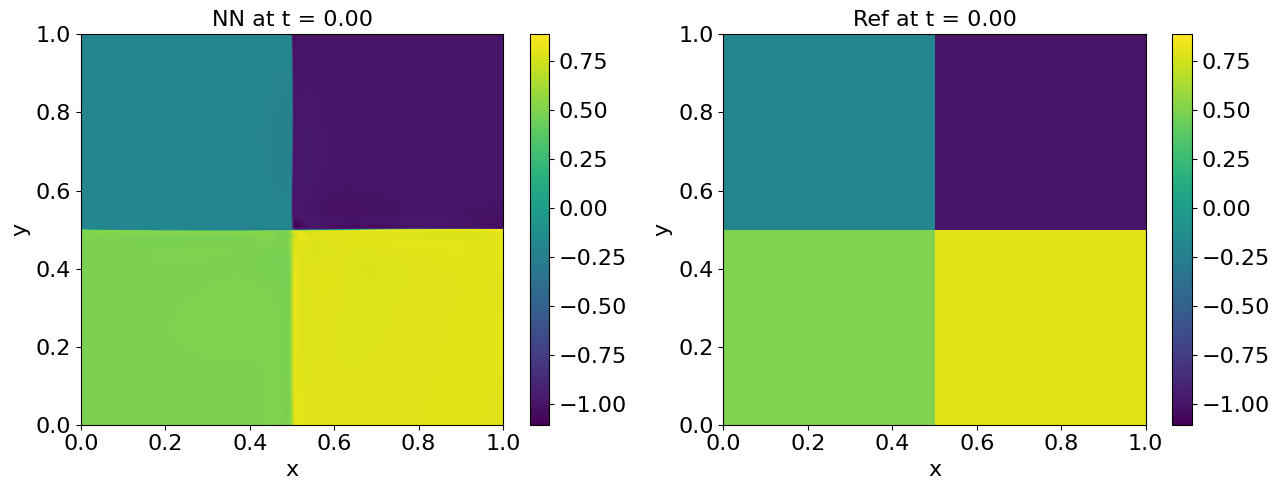

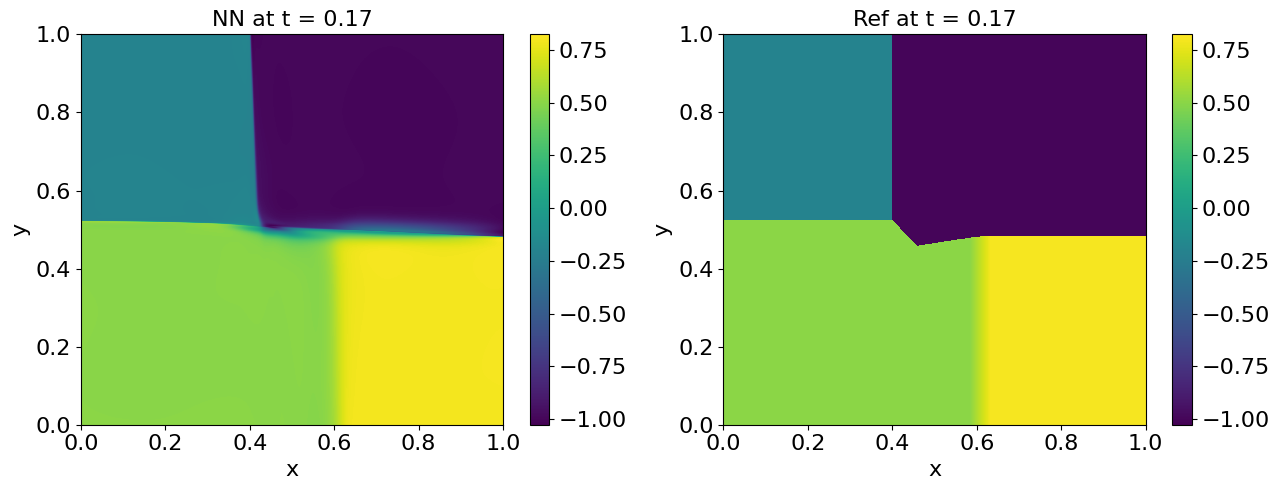

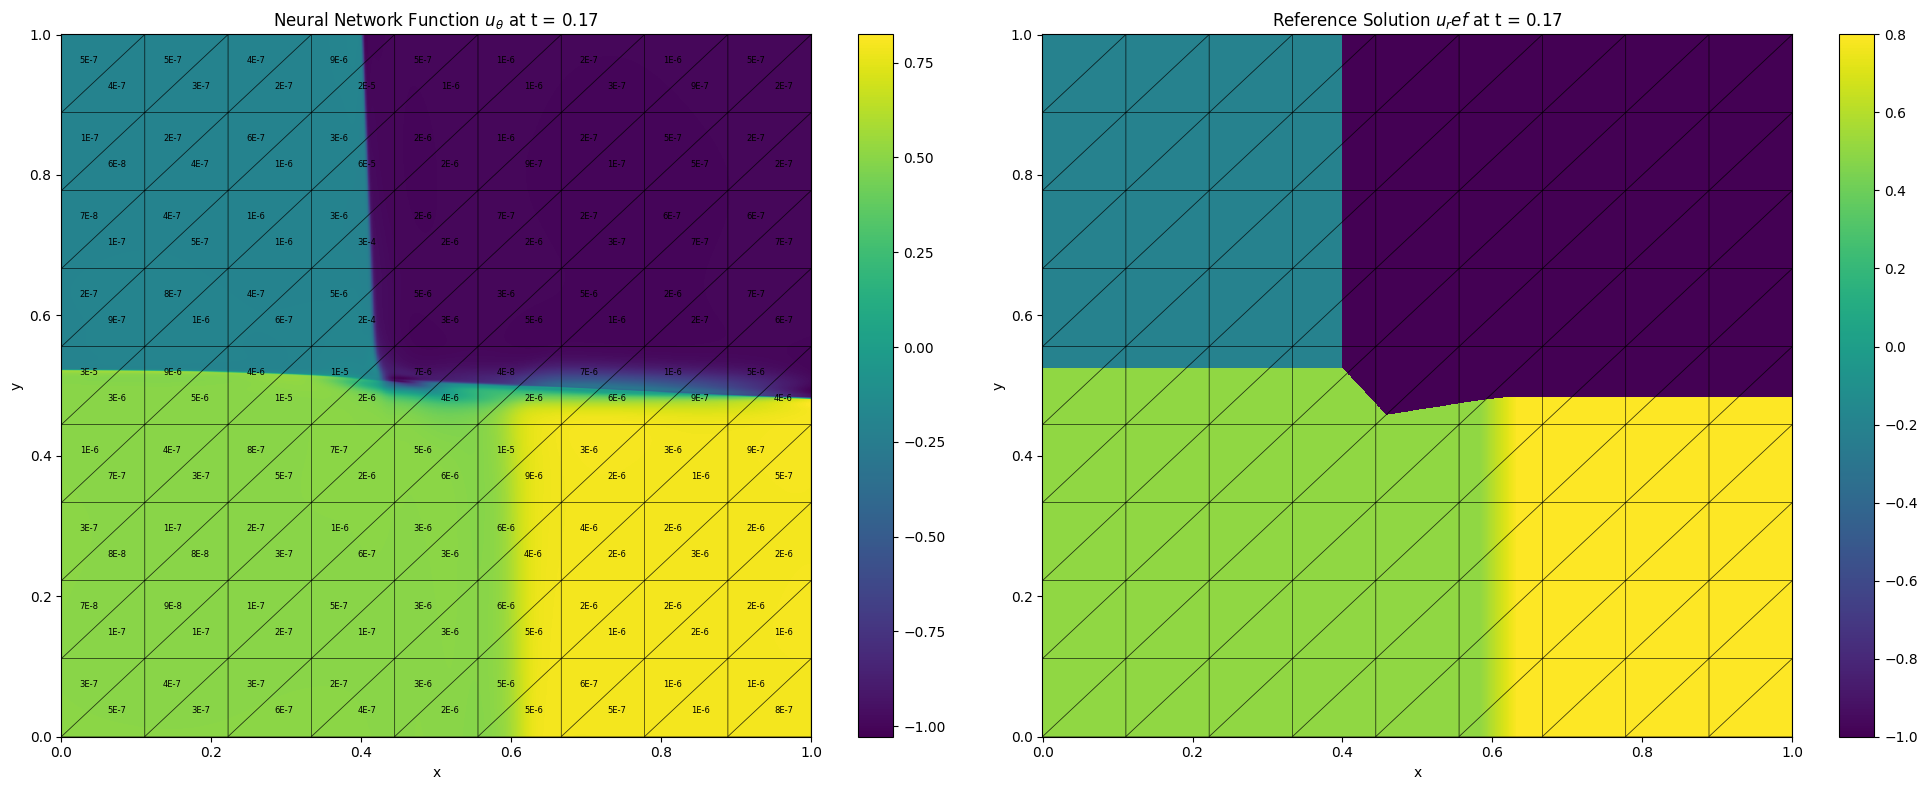

Updating importance sampling probabilities...
Grade 0, Iter 4100, loss_eqn: 0.016961, loss_eqn_from_kh: 0.016961 loss_l1: 0.065750, loss_ibc: 0.000791
Updating importance sampling probabilities...
Grade 0, Iter 4200, loss_eqn: 0.019076, loss_eqn_from_kh: 0.019075 loss_l1: 0.066904, loss_ibc: 0.000794
Updating importance sampling probabilities...
Grade 0, Iter 4300, loss_eqn: 0.015248, loss_eqn_from_kh: 0.015248 loss_l1: 0.063536, loss_ibc: 0.000834
Updating importance sampling probabilities...
Grade 0, Iter 4400, loss_eqn: 0.017176, loss_eqn_from_kh: 0.017176 loss_l1: 0.065466, loss_ibc: 0.000781
Updating importance sampling probabilities...
Grade 0, Iter 4500, loss_eqn: 0.014876, loss_eqn_from_kh: 0.014876 loss_l1: 0.063111, loss_ibc: 0.000768
Updating importance sampling probabilities...
Grade 0, Iter 4600, loss_eqn: 0.014428, loss_eqn_from_kh: 0.014428 loss_l1: 0.062709, loss_ibc: 0.000720
Updating importance sampling probabilities...
Grade 0, Iter 4700, loss_eqn: 0.015333, loss_eqn

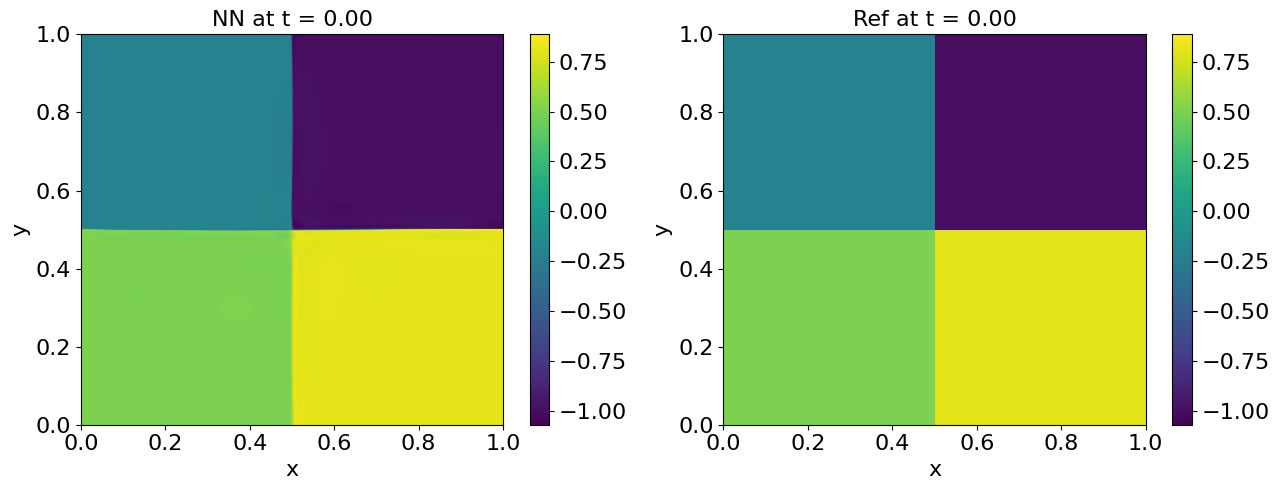

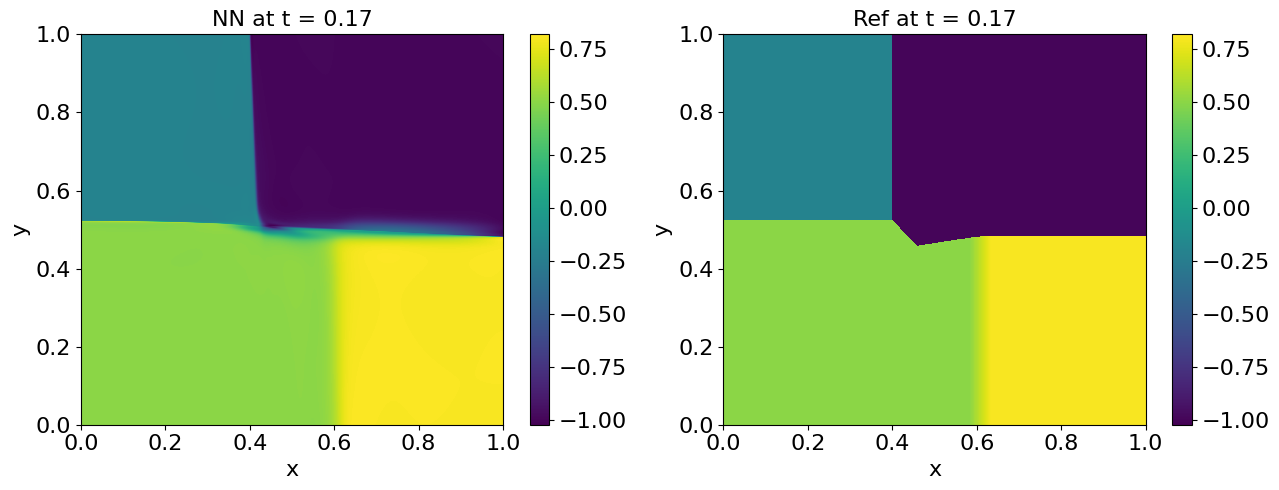

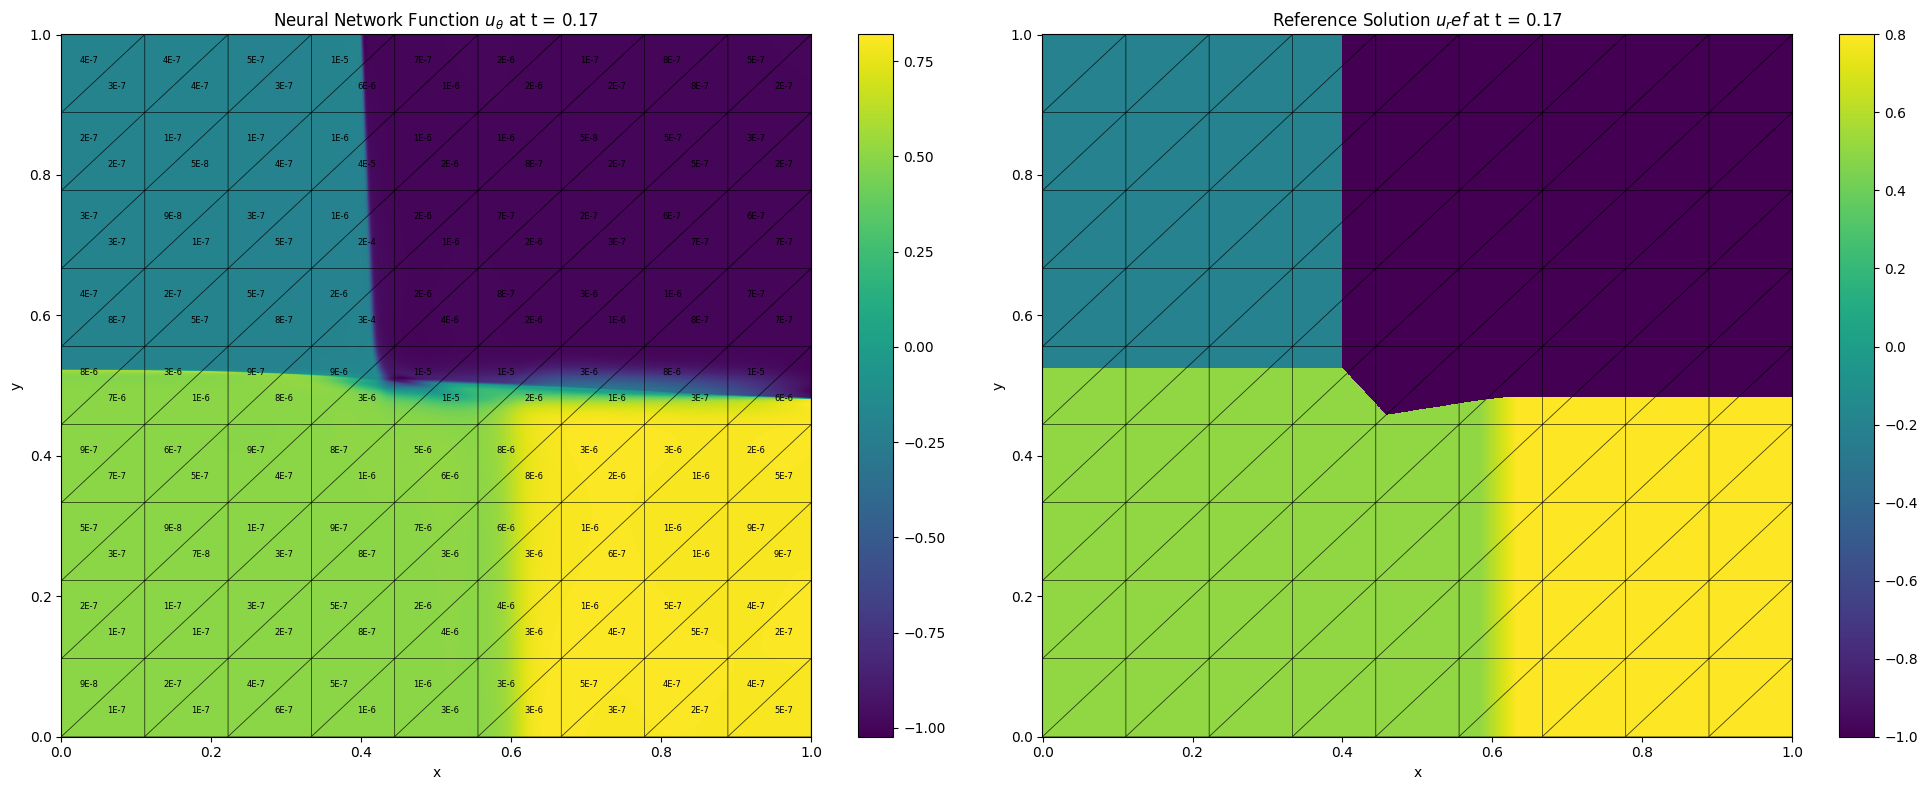

Updating importance sampling probabilities...
Grade 0, Iter 5100, loss_eqn: 0.015092, loss_eqn_from_kh: 0.015092 loss_l1: 0.061866, loss_ibc: 0.000719


In [ ]:
optprob.train_seq()

In [ ]:
def plot_u_theta_mesh(model, params=None, M_t=1000, M_x=2000, t_min=0.0, t_max=0.5, x_min=-1.0, x_max=1.0, y_min=None, y_max=None, M_y=None, ts=None, upload_fig=False, pwp=None, vals=None):
    """
    Plot the neural network function u_theta over a specified domain [t_min, t_max] x [x_min, x_max].
    Optionally overlay the mesh from PiecewiseLinearPolynomials and denote vals on the meshes.
    The 1D plot at t = t_max is removed, and only the 2D plot is shown.

    Args:
        model: Neural network u_theta.
        params: Parameters (pytree) of the neural network.
        M_t: Number of grid points in the t-direction (default: 1000).
        M_x: Number of grid points in the x-direction (default: 2000).
        t_min: Minimum value for t (default: 0.0).
        t_max: Maximum value for t (default: 0.5).
        x_min: Minimum value for x (default: -1.0).
        x_max: Maximum value for x (default: 1.0).
        y_min: Minimum value for y (for 3D cases, default: None).
        y_max: Maximum value for y (for 3D cases, default: None).
        M_y: Number of grid points in the y-direction (for 3D cases, default: None, falls back to M_x).
        ts: List or array of timestamps for which to plot individual 1D snapshots (default: None).
        upload_fig: Whether to upload the figure to wandb (default: False).
        pwp: Instance of PiecewiseLinearPolynomials(Tri/Rect/Hex/Tetra) to plot the mesh (default: None).
        vals: Values to denote on each mesh (default: None).
    """
    if ts is None:
        ts = []

    input_dim = model.input_dim if hasattr(model, 'input_dim') else 2
    if M_y is None:
        M_y = M_x

    if input_dim == 2:
        # Create a grid for t and x over the specified ranges
        t_grid = np.linspace(t_min, t_max, M_t)
        x_grid = np.linspace(x_min, x_max, M_x)
        t, x = np.meshgrid(t_grid, x_grid, indexing='ij')  # Shapes: (M_t, M_x)

        # Flatten the grid for batch evaluation
        tx_points = np.stack([t.ravel(), x.ravel()], axis=1)  # Shape: (M_t * M_x, 2)

        # Evaluate u_theta on the grid points
        if params is None:
            u_values = model.forward(tx_points)
        else:
            u_values = model.forward_with_params(params, tx_points) if hasattr(model, 'forward_with_params') else model(params, tx_points)
        u_values = u_values.reshape(M_t, M_x)  # Reshape to (M_t, M_x)

        # Create larger figure for the 2D plot
        t_range = t_max - t_min
        fig = plt.figure(figsize=(20, 8 + 8 * t_range))
        ax1 = fig.add_subplot(111)

        # 2D color mesh plot
        pcm = ax1.pcolormesh(x_grid, t_grid, u_values, shading='nearest', cmap='viridis')
        fig.colorbar(pcm, ax=ax1)
        ax1.set_xlabel('x')
        ax1.set_ylabel('t')
        ax1.set_title('Neural Network Function $u_\\theta$')

        # Overlay the mesh and denote vals if pwp and vals are provided
        if pwp is not None:
            if isinstance(pwp, PiecewiseLinearPolynomialsTri):
                triangles = pwp.partitions
                for idx, tri in enumerate(triangles):
                    # Plot the three edges of the triangle
                    ax1.plot([tri[0][1], tri[1][1]], [tri[0][0], tri[1][0]], color='black', alpha=0.5, linewidth=0.5)
                    ax1.plot([tri[1][1], tri[2][1]], [tri[1][0], tri[2][0]], color='black', alpha=0.5, linewidth=0.5)
                    ax1.plot([tri[2][1], tri[0][1]], [tri[2][0], tri[0][0]], color='black', alpha=0.5, linewidth=0.5)
                    center = np.mean(tri, axis=0)
                    if vals is not None:
                        # Denote avg_val at the center
                        ax1.text(center[1], center[0], f'{vals[idx]:.2f}', fontsize=6, color='black', ha='center', va='center')

            elif isinstance(pwp, PiecewiseLinearPolynomialsRect):
                rectangles = pwp.partitions
                for idx, rect in enumerate(rectangles):
                    # Plot the four edges of the rectangle
                    ax1.plot([rect[0][1], rect[1][1]], [rect[0][0], rect[1][0]], color='black', alpha=0.5, linewidth=0.5)  # Bottom
                    ax1.plot([rect[0][1], rect[2][1]], [rect[0][0], rect[2][0]], color='black', alpha=0.5, linewidth=0.5)  # Left
                    ax1.plot([rect[2][1], rect[3][1]], [rect[2][0], rect[3][0]], color='black', alpha=0.5, linewidth=0.5)  # Top
                    ax1.plot([rect[3][1], rect[1][1]], [rect[3][0], rect[1][0]], color='black', alpha=0.5, linewidth=0.5)  # Right
                    center = np.mean(rect, axis=0)
                    if vals is not None:
                        # Denote avg_val at the center
                        ax1.text(center[1], center[0], f'{vals[idx]:.2f}', fontsize=6, color='black', ha='center', va='center')

        # Adjust layout and display the main plot
        plt.tight_layout()
        # Upload the main figure to wandb
        if upload_fig:
            wandb.log({f"u_theta_tmin{t_min:.1f}_tmax_{t_max:.1f}": wandb.Image(fig)})
        plt.show()

    elif input_dim == 3:
        if y_min is None or y_max is None:
            raise ValueError("For input_dim=3, y_min and y_max must be provided.")

        # 2D plot at t = t_max over (x, y)
        x_grid = np.linspace(x_min, x_max, M_x)
        y_grid = np.linspace(y_min, y_max, M_y)
        x, y = np.meshgrid(x_grid, y_grid)  # Shapes: (M_x, M_y)
        
        t = t_max * np.ones_like(x)
        txy_points = np.stack([t.ravel(), x.ravel(), y.ravel()], axis=1)  # Shape: (M_x * M_y, 3)
        
        # Evaluate u_theta on the grid points
        if params is None:
            u_values = model.forward(txy_points)
        else:
            u_values = model.forward_with_params(params, txy_points) if hasattr(model, 'forward_with_params') else model(params, txy_points)
        u_values = u_values.reshape(M_y, M_x)  # Reshape to (M_x, M_y)
        
        # Create figure for the 2D plot at t_max
        fig = plt.figure(figsize=(10, 8))
        ax1 = fig.add_subplot(111)
        
        # 2D color mesh plot
        pcm = ax1.pcolormesh(x_grid, y_grid, u_values, shading='nearest', cmap='viridis')
        fig.colorbar(pcm, ax=ax1)
        ax1.set_xlabel('x')
        ax1.set_ylabel('y')
        ax1.set_title(f'Neural Network Function $u_\\theta$ at t = {t_max:.2f}')
        
        # Overlay the mesh and denote vals for elements sharing a face with t = t_max
        
        if pwp is not None:
            partitions = pwp.partitions
            # Find elements that share a face with t = t_max (i.e., max t == t_max)
            max_t_per_elem = np.max(partitions[:, :, 0], axis=1)
            surface_mask = np.isclose(max_t_per_elem, t_max, atol=1e-6)
            surface_elems = partitions[surface_mask]
            surface_indices = np.where(surface_mask)[0]
            
            if isinstance(pwp, PiecewiseLinearPolynomialsHex):
                
                for i, hex_elem in enumerate(surface_elems):
                    # Find vertices at t = t_max (top face)
                    top_mask = np.isclose(hex_elem[:, 0], t_max, atol=1e-6)
                    top_verts = hex_elem[top_mask]
                    if len(top_verts) == 4:  # Expected for hex top face
                        x_top = top_verts[:, 1]
                        y_top = top_verts[:, 2]
                        # Order for closed rectangle: assuming vertices [lowx lowy, lowx highy, highx lowy, highx highy]
                        # Indices based on binary order: 0: lowx lowy, 1: lowx highy, 2: highx lowy, 3: highx highy
                        indices = np.array([0, 1, 3, 2])
                        ax1.plot(np.append(x_top[indices], x_top[indices[0]]), np.append(y_top[indices], y_top[indices[0]]), 
                                 color='black', alpha=0.5, linewidth=0.5)
                        
                        center_x = np.mean(x_top)
                        center_y = np.mean(y_top)
                        if vals is not None:
                            ax1.text(center_x, center_y, f'{vals[surface_indices[i]]:.2f}', fontsize=6, color='black', ha='center', va='center')
            
            elif isinstance(pwp, PiecewiseLinearPolynomialsTetra):
                for i, tet in enumerate(surface_elems):
                    # Find vertices at t = t_max
                    top_mask = np.isclose(tet[:, 0], t_max, atol=1e-6)
                    top_verts = tet[top_mask]
                    if len(top_verts) == 3:  # Triangle face
                        x_top = top_verts[:, 1]
                        y_top = top_verts[:, 2]
                        ax1.plot(np.append(x_top, x_top[0]), np.append(y_top, y_top[0]), 
                                 color='black', alpha=0.5, linewidth=0.5)
                        
                        center_x = np.mean(x_top)
                        center_y = np.mean(y_top)
                        if vals is not None:
                            ax1.text(center_x, center_y, f'{vals[surface_indices[i]]:.2f}', fontsize=6, color='black', ha='center', va='center')
            else:
                print("No such class!!!")
        plt.tight_layout()
        # Upload the figure to wandb
        if upload_fig:
            wandb.log({f"u_theta_at_tmax_{t_max:.1f}": wandb.Image(fig)})
        plt.show()

    # Plot separate figures for each timestamp in ts (adapted for dimension)
    for t_val in ts:
        if input_dim == 2:
            # Find the closest index in t_grid
            idx = np.argmin(np.abs(t_grid - t_val))
            # Create a new figure for the snapshot
            fig, ax = plt.subplots(1, 1, figsize=(10, 4))
            ax.plot(x_grid, u_values[idx, :])
            ax.set_xlabel('x')
            ax.set_ylabel('$u_\\theta(t, x)$')
            ax.set_title(f'Neural Network Function at t = {t_val:.2f} (closest t = {t_grid[idx]:.2f})')
            plt.tight_layout()
            plt.show()
        elif input_dim == 3:
            # Similar to t_max plot but without mesh/vals (or adapt if needed)
            x, y = np.meshgrid(x_grid, y_grid)
            t = t_val * np.ones_like(x)
            txy_points = np.stack([t.ravel(), x.ravel(), y.ravel()], axis=1)
            u_values_ts = model.forward(txy_points).reshape(M_y, M_x)
            fig_ts, ax_ts = plt.subplots(1, 1, figsize=(10, 8))
            pcm_ts = ax_ts.pcolormesh(x_grid, y_grid, u_values_ts, shading='nearest', cmap='viridis')
            fig_ts.colorbar(pcm_ts, ax=ax_ts)
            ax_ts.set_xlabel('x')
            ax_ts.set_ylabel('y')
            ax_ts.set_title(f'Neural Network Function $u_\\theta$ at t = {t_val:.2f}')
            plt.tight_layout()
            plt.show()

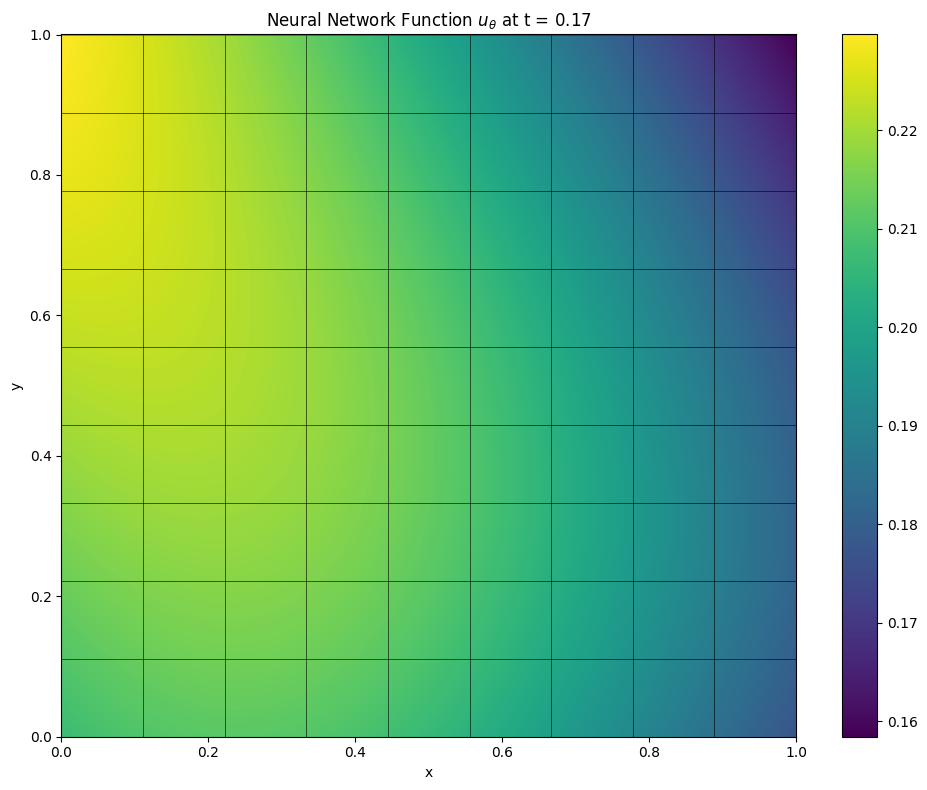

In [7]:
self = optprob.segments[0]
plot_u_theta_mesh(self.model, t_min=self.t_min, t_max=self.t_max, x_min=self.x_min,
                            x_max=self.x_max, y_min=0, y_max=1, pwp=self.pwp)

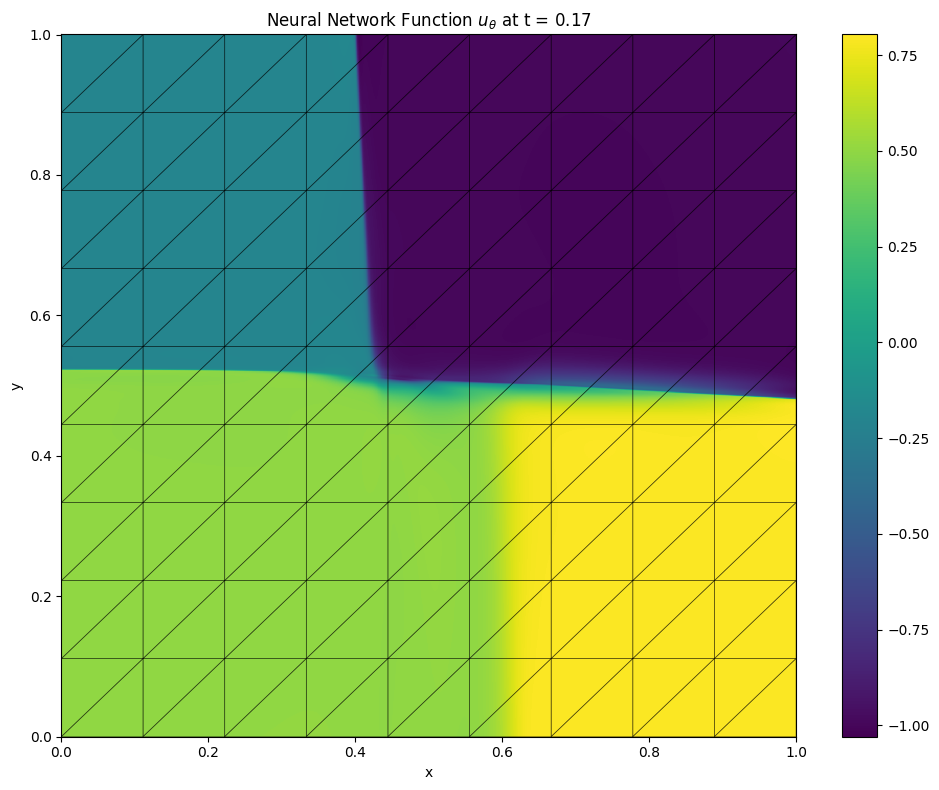

In [37]:
self = optprob.segments[0]
plot_u_theta_mesh(self.model, t_min=self.t_min, t_max=self.t_max, x_min=self.x_min,
                            x_max=self.x_max, y_min=0, y_max=1, pwp=self.pwp)

In [12]:
import numpy as np

def u_ref(t, x, y):
    """
    Reference solution u(t, x, y).
    Returns 0 if y > 0.5 + 0.5*t, else 1.
    """
    return np.where(y > 0.5 + 0.5 * t, 0, 1)

def u0(x, y):
    """
    Initial condition u0(x, y) = u(0, x, y).
    """
    return u_ref(t_min*np.zeros_like(x), x, y)

def u_left(t, y):
    """
    Boundary condition at x = x_min (independent of x, so same as u_ref).
    """
    return u_ref(t, np.zeros_like(y), y)  # x=0 as placeholder, since independent of x

def u_right(t, y):
    """
    Boundary condition at x = x_max (independent of x, so same as u_ref).
    """
    return u_ref(t, np.zeros_like(y), y)  # x=0 as placeholder

def u_bottom(t, x):
    """
    Boundary condition at y = y_min (independent of x, so same as u_ref with y=y_min).
    """
    return u_ref(t, x, np.zeros_like(x))  # y=0 as placeholder, but function needs y

def u_top(t, x):
    """
    Boundary condition at y = y_max (independent of x, so same as u_ref with y=y_max).
    """
    return u_ref(t, x, np.ones_like(x))  # y=0 as placeholder, adjust if y_max known

def res(u_quad, u_t, u_x, u_y):
    return u_t + u_quad * u_x + u_quad * u_y

In [13]:
t_min = 0
t_max = 0.5
x_min = 0
x_max = 1
y_min = 0
y_max = 1
N_t = 8
N_x = 9
N_y = 9
optprob = SeqMinMaxOptProb(input_dim=3, total_t_min=t_min, total_t_max=t_max, x_min=x_min, x_max=x_max, y_min=y_min, y_max=y_max,
    N_t=N_t, N_x=N_x, N_y=N_y, N_bc=128, N_ic=128,
    hidden_dims_list=[[64, 64, 64, 64, 64]], seed=0,
    sigma=10, N_perturb=50000, k_h_rf_times=2, f_adaptive_weight=2000, f_opt_kh=1,
    u0=u0, u1=u_left, u2=u_right, u3=u_bottom, u4=u_top, project="seq_minmax_burgers2D",
    lambda_ic=20.0, lambda_bc=20.0, lambda_eqn=1.0,
    gamma=0, N_test_gamma=1000, adjust_gamma=False,
    L1reg=0, sampling_method='uniform', notes='', pre_epochs=0,
    init_lrs=[2e-4, 1e-3, 1e-3], grade_epochs=[101, 1000, 1000], decay_rates=[1e-3, 1e-3, 1e-3],
    res=res, loss_type='interior', k=0, f_plot=2000, partition='hex', u_ref=u_ref,
    set_wandb=False
)

Adding grade 1 with hidden dims [64, 64, 64, 64, 64]

Training segment [0.0000, 0.5000]
Skipping pre-training as pre_epochs is set to 0.

Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0
The largest W^{1,inf} norm of k_h coeffs is 9.413791
Grade 0, Iter 0, lambda_ic: 18.335306, lambda_bc: 18.339373, lambda_eqn: 1.145638
Grade 0, Iter 0, loss_eqn: 0.410825, loss_eqn_from_kh: 0.410592, loss_l1: 0.410592, loss_ibc: 3.018623


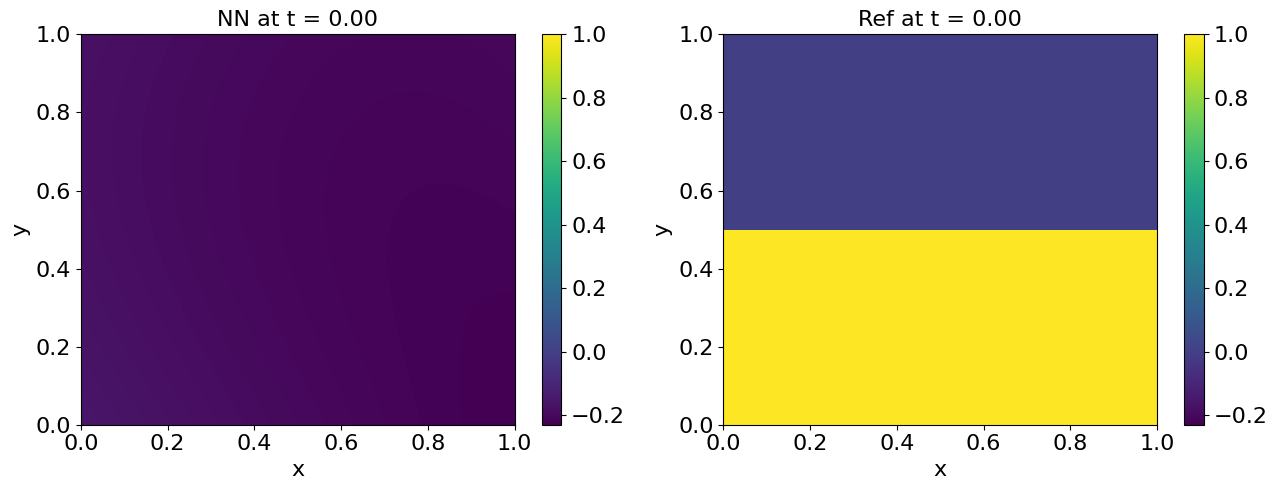

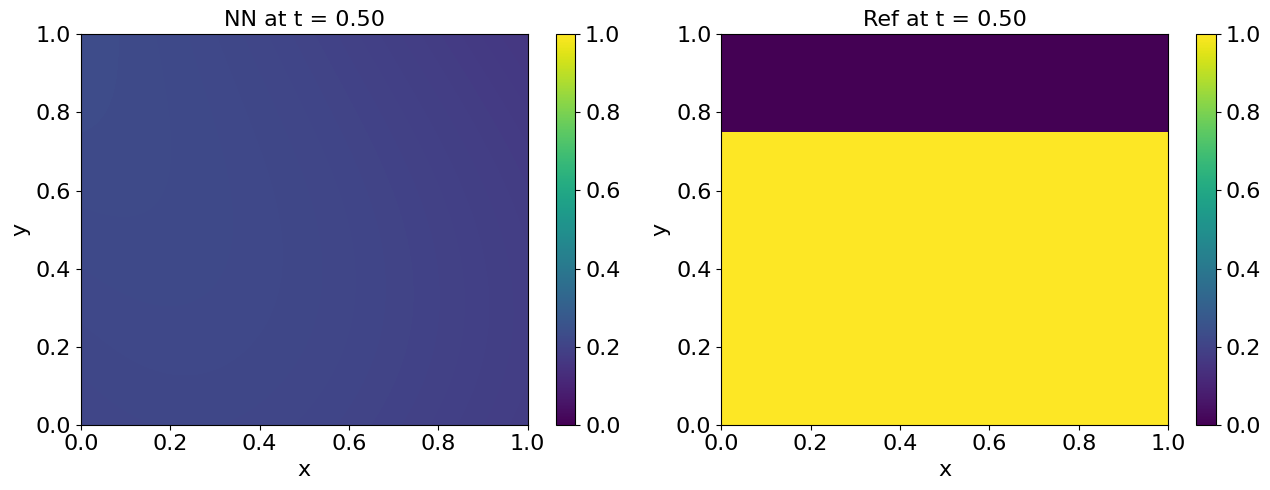

Grade 0, Iter 100, loss_eqn: 0.234396, loss_eqn_from_kh: 0.234049, loss_l1: 0.234049, loss_ibc: 0.275619
Train time for stage1: 92.617730 seconds

Plotting after training segment [0.0000, 0.5000]


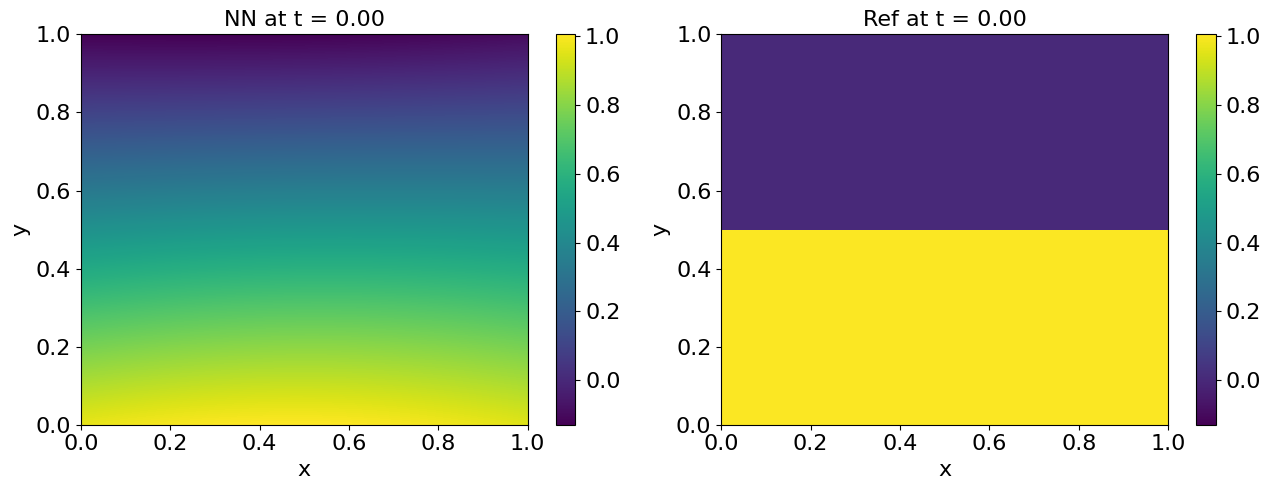

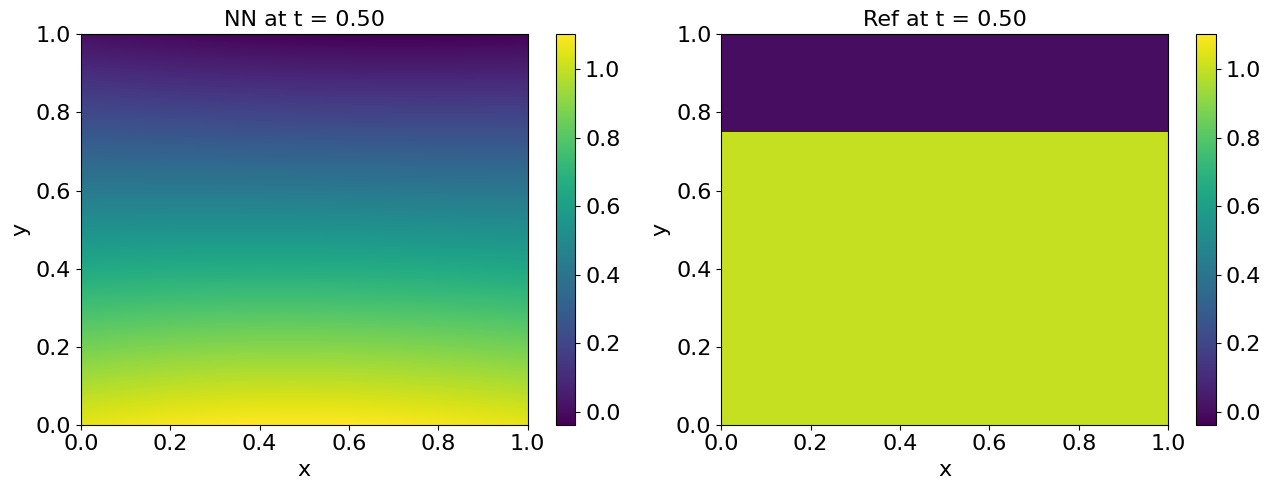

In [14]:
optprob.train_seq()

In [7]:
self = optprob.segments[0]
self.input_dim
self.u_ref(0.5, 1, 0.5)

IndexError: list index out of range

In [ ]:
plot_u_2D([0, 0.5], u_ref, nx=1000, ny=1000)

In [8]:
self = optprob
params = optprob.model.mlps[0].params
self.gen_funcs(0)
self.pwp.coeffs, self.key, loss_eqn_from_kh, loss_l1, loss_each_elem = self.maximize_kh_step(params, self.key)

In [9]:
Nt = self.pwp.N_elements
quad_points = self.pwp.quad_points_parti
u_values_all = self.u_eval(params, quad_points)
quad_weights = self.pwp.quad_weights_parti
avg_vals = jnp.einsum('ij,ij->i', u_values_all, quad_weights)/self.elem_meas
init_coeffs_all = jnp.hstack([avg_vals[..., None] , jnp.zeros((Nt, self.p_dof - 1))])
perturbations_all = self.sigma * jax.random.uniform(self.key, (self.N_perturb, self.p_dof), minval=-1, maxval=1)
perturbed_coeffs_all = init_coeffs_all[:, None, :] + perturbations_all[None, :, :]

In [35]:
parti_idx = 0
quad_points = self.pwp.quad_points_parti[parti_idx]
quad_weights = self.pwp.quad_weights_parti[parti_idx]
u_quad = self.u_eval(params, quad_points)
grad_u_tx = self.grad_u(params, quad_points)

In [36]:
quad_points.shape

(64, 3)

In [11]:
u_t, u_x, u_y = grad_u_tx[:, 0], grad_u_tx[:, 1], grad_u_tx[:, 2]
residual = self.res(u_quad, u_t, u_x, u_y).flatten()
p_coeffs_all = perturbed_coeffs_all[parti_idx]
k_h_quad_all = (p_coeffs_all[:, 0][:, None] + 
                p_coeffs_all[:, 1][:, None] * quad_points[:, 0] + 
                p_coeffs_all[:, 2][:, None] * quad_points[:, 1] + 
                p_coeffs_all[:, 3][:, None] * quad_points[:, 2]
               )
k_h_quad_all1 = jnp.einsum('ik,kj->ij', p_coeffs_all[:, 1:], quad_points.T) + p_coeffs_all[:, 0][:, None]

In [12]:
jnp.min(k_h_quad_all1-k_h_quad_all)

Array(-9.536743e-07, dtype=float32)

In [33]:
quad_points = self.pwp.quad_points
p_coeffs_quad = self.pwp.coeffs[self.pwp.element_indices]
k_h_quad = p_coeffs_quad[:, 0] + jnp.sum(p_coeffs_quad[:, 1:] * quad_points, axis=1)
k_h_quad1 = jnp.einsum('ij, ij->i', p_coeffs_quad[:, 1:], quad_points) + p_coeffs_quad[:, 0]

In [34]:
jnp.max(jnp.abs(k_h_quad-k_h_quad1))

Array(0., dtype=float32)

In [ ]:
jnp.max(k_h_quad-k_h_quad1)

In [28]:
jnp.sum(p_coeffs_quad[:, 1:] * quad_points, axis=1).shape

(41472,)

In [37]:
self.pwp.quad_points.shape

(41472, 3)

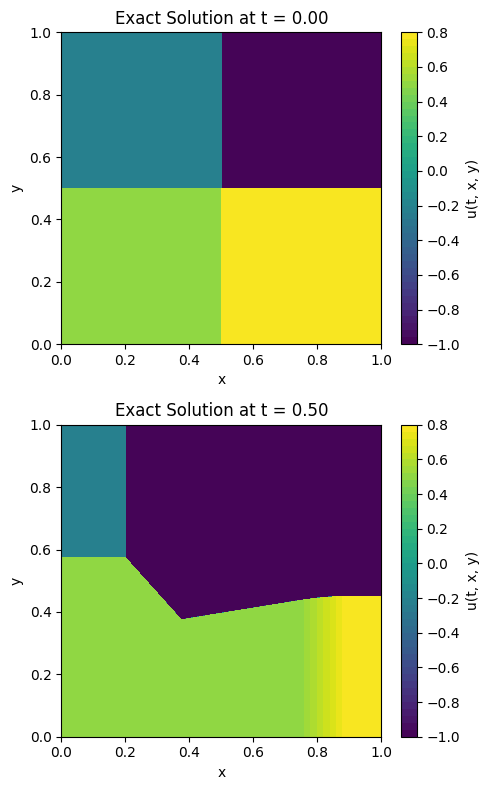

In [12]:
plot_u_2D([0, 0.5], u_ref, nx=1000, ny=1000)

In [77]:
N_t = 10  # Divisions in t
N_x = 5  # Divisions in x
N_y = 2  # Divisions in y
t_min = 0.0
t_max = 1
x_min = -1.0
x_max = 1.0
y_min = 0.0
y_max = 2.0

tau = (t_max - t_min) / N_t
hx = (x_max - x_min) / N_x
hy = (y_max - y_min) / N_y
t_starts = jnp.linspace(t_min, t_max - tau, N_t)
x_starts = jnp.linspace(x_min, x_max - hx, N_x)
y_starts = jnp.linspace(y_min, y_max - hy, N_y)
tl, xl, yl = jnp.meshgrid(t_starts, x_starts, y_starts, indexing='ij')
# Define the 8 vertices for each hexahedron using binary offsets
offsets_bin = jnp.array([[int(b) for b in f'{i:03b}'] for i in range(8)], dtype=jnp.float32)  # (8,3) binary 000 to 111
deltas = jnp.array([tau, hx, hy])
offsets = offsets_bin * deltas  # (8,3)
lowers = jnp.stack([tl.ravel(), xl.ravel(), yl.ravel()], axis=1)[:, None, :]  # (N_elements, 1, 3)
partitions = lowers + offsets[None, :, :]  # (N_elements, 8, 3)

In [83]:
tl, xl, yl = jnp.meshgrid(t_starts, x_starts, y_starts)
xl.shape

(5, 10, 2)

In [82]:
tl

Array([[[0. , 0. ],
        [0.1, 0.1],
        [0.2, 0.2],
        [0.3, 0.3],
        [0.4, 0.4],
        [0.5, 0.5],
        [0.6, 0.6],
        [0.7, 0.7],
        [0.8, 0.8],
        [0.9, 0.9]],

       [[0. , 0. ],
        [0.1, 0.1],
        [0.2, 0.2],
        [0.3, 0.3],
        [0.4, 0.4],
        [0.5, 0.5],
        [0.6, 0.6],
        [0.7, 0.7],
        [0.8, 0.8],
        [0.9, 0.9]],

       [[0. , 0. ],
        [0.1, 0.1],
        [0.2, 0.2],
        [0.3, 0.3],
        [0.4, 0.4],
        [0.5, 0.5],
        [0.6, 0.6],
        [0.7, 0.7],
        [0.8, 0.8],
        [0.9, 0.9]],

       [[0. , 0. ],
        [0.1, 0.1],
        [0.2, 0.2],
        [0.3, 0.3],
        [0.4, 0.4],
        [0.5, 0.5],
        [0.6, 0.6],
        [0.7, 0.7],
        [0.8, 0.8],
        [0.9, 0.9]],

       [[0. , 0. ],
        [0.1, 0.1],
        [0.2, 0.2],
        [0.3, 0.3],
        [0.4, 0.4],
        [0.5, 0.5],
        [0.6, 0.6],
        [0.7, 0.7],
        [0.8, 0.8],
        [0.9

In [69]:
# Gauss-Legendre nodes and weights in [-1, 1]
nodes, weights = np.polynomial.legendre.leggauss(3)
nodes_jnp = jnp.array(nodes)
weights_jnp = jnp.array(weights)

# Tensor product for 3D
t_nodes, x_nodes, y_nodes = jnp.meshgrid(nodes_jnp, nodes_jnp, nodes_jnp)

In [79]:
tl, xl, yl = jnp.meshgrid(t_starts, x_starts, y_starts, indexing='ij')
tl.shape

(10, 5, 2)

In [72]:
t_nodes

Array([[[-0.7745967, -0.7745967, -0.7745967],
        [ 0.       ,  0.       ,  0.       ],
        [ 0.7745967,  0.7745967,  0.7745967]],

       [[-0.7745967, -0.7745967, -0.7745967],
        [ 0.       ,  0.       ,  0.       ],
        [ 0.7745967,  0.7745967,  0.7745967]],

       [[-0.7745967, -0.7745967, -0.7745967],
        [ 0.       ,  0.       ,  0.       ],
        [ 0.7745967,  0.7745967,  0.7745967]]], dtype=float32)

In [73]:
x_nodes

Array([[[-0.7745967, -0.7745967, -0.7745967],
        [-0.7745967, -0.7745967, -0.7745967],
        [-0.7745967, -0.7745967, -0.7745967]],

       [[ 0.       ,  0.       ,  0.       ],
        [ 0.       ,  0.       ,  0.       ],
        [ 0.       ,  0.       ,  0.       ]],

       [[ 0.7745967,  0.7745967,  0.7745967],
        [ 0.7745967,  0.7745967,  0.7745967],
        [ 0.7745967,  0.7745967,  0.7745967]]], dtype=float32)

Text(0.5, 1.0, 'Neural Network Function $u_\\theta$ at t = 1.00')

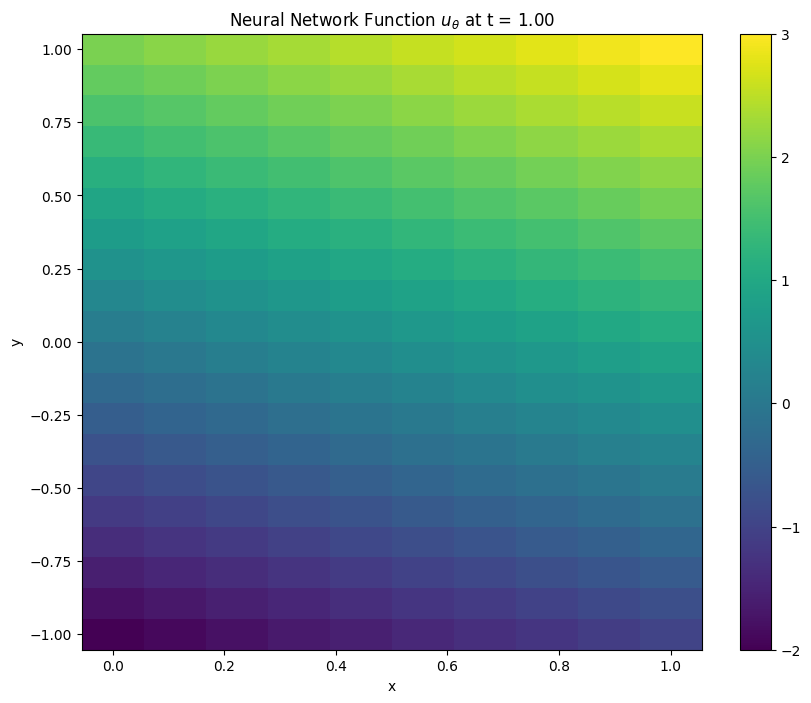

In [70]:
x_min = 0
x_max = 1
M_x = 10
y_min = -1
y_max = 1
M_y = 20
t_max = 1
# 2D plot at t = t_max over (x, y)
x_grid = np.linspace(x_min, x_max, M_x)
y_grid = np.linspace(y_min, y_max, M_y)
x, y = np.meshgrid(x_grid, y_grid, indexing='ij')  # Shapes: (M_x, M_y)
        
t = t_max * np.ones_like(x)
txy_points = np.stack([t.ravel(), x.ravel(), y.ravel()], axis=1)  # Shape: (M_x * M_y, 3)
        
# Evaluate u_theta on the grid points
u_values = txy_points[:,1]+2*txy_points[:,2]
u_values = u_values.reshape(x.shape)  # Reshape to (M_y, M_x)
        
# Create figure for the 2D plot at t_max
fig = plt.figure(figsize=(10, 8))
ax1 = fig.add_subplot(111)
        
# 2D color mesh plot
pcm = ax1.pcolormesh(x_grid, y_grid, u_values.T, shading='nearest', cmap='viridis')
fig.colorbar(pcm, ax=ax1)
ax1.set_xlabel('x')
ax1.set_ylabel('y')
ax1.set_title(f'Neural Network Function $u_\\theta$ at t = {t_max:.2f}')

In [56]:
x_grid.shape

(10,)

In [54]:
x, y = np.meshgrid(x_grid, y_grid)

In [55]:
x.shape

(20, 10)

In [58]:
x, y = np.meshgrid(x_grid, y_grid, indexing='ij')

In [6]:
jnp.maximum(jnp.ones(10), 0)

Array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1.], dtype=float32)

In [6]:
print(f'{0.000123: .1e}')

 1.2e-04


In [ ]:
ax1.text(center[1], center[0], f'{vals[idx]: .0e}', fontsize=4, color='black', ha='center', va='center', clip_on=True, bbox=dict(facecolor='white', alpha=0.5, pad=1))

In [ ]:
ax1.text(center[1], center[0], f'{vals[idx]: .0e}', fontsize=4, color='black', ha='center', va='center', clip_on=True, bbox=dict(facecolor='white', alpha=0.5, pad=1))